# Imports, paths, and shared settings

In [12]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from adjustText import adjust_text
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
from scipy.spatial import ConvexHull, QhullError


# ---------------------------------------------------------------------
# 1. Locate the repository's data directory
# ---------------------------------------------------------------------
INPUT_SUBDIR = "Input_data"
OUTPUT_SUBDIR = "Output_data"
MAIN_DATA_FILENAME = "Damage_and_Pop_by_CT_WIDE_FORMAT_by_type.csv"

# Python scripts use their own location; notebooks use the working directory.
if "__file__" in globals():
    base_dir = Path(__file__).resolve().parent
else:
    base_dir = Path.cwd().resolve()

# Support execution from either Script/ or the repository root.
candidate_directories = [
    base_dir / "Data",
    base_dir.parent / "Data",
]

# Probe for the sentinel file at the path we will actually read from.
SENTINEL = Path(OUTPUT_SUBDIR) / MAIN_DATA_FILENAME

DATA_DIR = next(
    (d.resolve() for d in candidate_directories if (d / SENTINEL).is_file()),
    None,
)

if DATA_DIR is None:
    searched = "\n".join(f"  {d / SENTINEL}" for d in candidate_directories)
    raise FileNotFoundError(
        f"Could not locate {SENTINEL}.\n"
        f"Searched:\n{searched}\n"
        f"(cwd is {Path.cwd()})\n"
        "Run from the repository root or the Script directory."
    )

INPUT_DIR = DATA_DIR / INPUT_SUBDIR
OUTPUT_DIR = DATA_DIR / OUTPUT_SUBDIR

TRACT_DATA_PATH      = OUTPUT_DIR / MAIN_DATA_FILENAME
PROPERTY_VALUE_PATH  = OUTPUT_DIR / "total_property_value_by_census_tract.csv"
INUNDATION_DATA_PATH = OUTPUT_DIR / "total_flooded_area_all_msas.csv"
MSA_MAPPING_PATH     = INPUT_DIR  / "CBSA"/"cbsa_to_county_fips.json"

for path in [
    TRACT_DATA_PATH,
    PROPERTY_VALUE_PATH,
    INUNDATION_DATA_PATH,
    MSA_MAPPING_PATH,
]:
    if not path.is_file():
        raise FileNotFoundError(f"Required data file not found: {path}")

print(f"Data directory: {DATA_DIR}")


# ---------------------------------------------------------------------
# 2. Analysis settings
# ---------------------------------------------------------------------
HEIGHT_CODES = tuple(range(5, 55, 5))
HEIGHTS_M = np.asarray(HEIGHT_CODES) / 10

DAMAGE_SUFFIX = "50"
DAMAGE_THRESHOLD_FRACTION = 0.05
POPULATION_THRESHOLD_FRACTION = 0.05
GROUP_SIZE = 3


# ---------------------------------------------------------------------
# 3. FEMA region mapping
# ---------------------------------------------------------------------
REGION_TO_FIPS = {
    "FEMA 1": {"09", "23", "25", "33", "44", "50"},
    "FEMA 2": {"34", "36"},
    "FEMA 3": {"10", "11", "24", "42", "51", "54"},
    "FEMA 4": {"01", "12", "13", "21", "28", "37", "45", "47"},
    "FEMA 6": {"05", "22", "35", "40", "48"},
}

FIPS_TO_REGION = {
    state_fips: region
    for region, state_codes in REGION_TO_FIPS.items()
    for state_fips in state_codes
}

REGION_ORDER = list(REGION_TO_FIPS)


# ---------------------------------------------------------------------
# 4. Shared sensitivity-group styles
# ---------------------------------------------------------------------
GROUP_STYLES = {
    "High Sensitivity Group": {
        "color": "#CC0000",
        "fill": "#FF9999",
        "marker": "o",
    },
    "Medium Sensitivity Group": {
        "color": "#228B22",
        "fill": "#A9DFBF",
        "marker": "s",
    },
    "Low Sensitivity Group": {
        "color": "#003399",
        "fill": "#99CCFF",
        "marker": "^",
    },
}


# ---------------------------------------------------------------------
# 5. Selected MSA labels for the risk scatterplots
# ---------------------------------------------------------------------
MSAS_TO_LABEL = {
    "Boston", "Portland", "Providence", "Bangor",
    "Vineland", "New York", "Atlantic City",
    "Philadelphia", "Baltimore", "Richmond", "Washington",
    "Salisbury", "Dover", "Greenville", "Miami", "Mobile",
    "Charleston", "Wilmington", "Victoria", "New Orleans",
    "Beaumont", "Houston", "Baton Rouge",
}

Data directory: C:\Users\wanh535\OneDrive - PNNL\Documents\PyCharmProjects\Wan_et_al_2026_Nature_Comms\Data


# Data preparation

In [15]:
# ---------------------------------------------------------------------
# 1. General helper functions
# ---------------------------------------------------------------------
def require_columns(data, columns):
    """Raise an error when required columns are missing."""
    missing = sorted(set(columns) - set(data.columns))

    if missing:
        raise KeyError(f"Missing required columns: {missing}")


def normalize_fips(data, width):
    """Validate and convert FIPS identifiers to zero-padded strings."""
    codes = (
        data.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

    valid = codes.str.fullmatch(rf"\d{{1,{width}}}", na=False)

    if not valid.all():
        examples = data.loc[~valid].head().tolist()
        raise ValueError(
            f"Invalid FIPS identifiers for width {width}: {examples}"
        )

    return codes.str.zfill(width)


def clean_name_for_variable(name):
    """Convert an MSA name into a consistent dictionary key."""
    name = re.sub(r"[\s/-]+", "_", str(name))
    name = re.sub(r"[^\w]", "", name)

    return re.sub(r"_+", "_", name).strip("_").lower()


def normalize_msa_name(name):
    """Normalize MSA names for matching across source datasets."""
    if pd.isna(name):
        return ""

    name = re.sub(
        r"\s+MSA\s*$",
        "",
        str(name),
        flags=re.IGNORECASE,
    )

    return "".join(
        character
        for character in name.lower()
        if character.isalnum()
    )


def get_short_msa_name(name):
    """Extract a short MSA label for plotting."""
    if pd.isna(name):
        return ""

    return re.split(r"[-–,]", str(name))[0].strip()


# ---------------------------------------------------------------------
# 2. Prepare tract data and join property values
# ---------------------------------------------------------------------
def prepare_tract_data(data, property_data):
    """
    Join property values to the main tract dataset using GEOID.

    Main-data aliases:
        Total_Damage_Loss <- A_50_50
        Total_Pop         <- Pop_50_2020

    External property-value field:
        Total_Property_Value

    All main-data records are retained. Property-file GEOIDs must be
    unique so that the left join does not multiply records.
    """
    require_columns(
        data,
        ["GEOID", "A_50_50", "Pop_50_2020"],
    )
    require_columns(
        property_data,
        ["GEOID", "Total_Property_Value"],
    )

    data = data.copy()
    property_data = property_data[
        ["GEOID", "Total_Property_Value"]
    ].copy()

    # Standardize identifiers in both datasets before joining.
    data["GEOID"] = normalize_fips(data["GEOID"], width=11)
    property_data["GEOID"] = normalize_fips(
        property_data["GEOID"],
        width=11,
    )

    # Validate property-file uniqueness after GEOID normalization.
    duplicate_property_mask = property_data["GEOID"].duplicated(
        keep=False
    )

    if duplicate_property_mask.any():
        examples = (
            property_data.loc[duplicate_property_mask, "GEOID"]
            .drop_duplicates()
            .head(10)
            .tolist()
        )

        raise ValueError(
            "The property-value file must contain one row per GEOID. "
            f"Duplicate examples: {examples}. "
            "Inspect these records before deduplicating or aggregating."
        )

    property_data["Total_Property_Value"] = pd.to_numeric(
        property_data["Total_Property_Value"],
        errors="raise",
    )

    # Remove old derived fields if present. The external file is the
    # authoritative source for Total_Property_Value.
    data = data.drop(
        columns=[
            "Total_Damage_Loss",
            "Total_Pop",
            "Total_Property_Value",
            "state",
            "county_fips",
            "FEMA_region",
        ],
        errors="ignore",
    )

    data = data.astype({
        "A_50_50": "float64",
        "Pop_50_2020": "float64",
    })

    # Preserve the earlier convention for main-data numeric gaps.
    # Do this BEFORE joining so missing property values remain missing.
    numeric_columns = data.select_dtypes(include="number").columns

    data = data.fillna({
        column: 0
        for column in numeric_columns
    }).copy()

    # Report existing main-data duplicates without changing them.
    duplicate_main_mask = data["GEOID"].duplicated(keep=False)
    duplicate_main_count = data.loc[
        duplicate_main_mask, "GEOID"
    ].nunique()

    if duplicate_main_count > 0:
        warnings.warn(
            f"The main dataset contains {duplicate_main_count:,} "
            "GEOIDs with multiple records. These records are retained. "
            "The property join will not add rows, but aggregating "
            "repeated tract records can still double-count exposure "
            "or property values.",
            stacklevel=2,
        )

    # Left join: retain main-data rows without adding property-only tracts.
    original_count = len(data)

    unmatched_geoids = data.loc[
        ~data["GEOID"].isin(property_data["GEOID"]),
        "GEOID",
    ].drop_duplicates()

    data = data.merge(
        property_data,
        on="GEOID",
        how="left",
        validate="many_to_one",
        sort=False,
    )

    assert len(data) == original_count, (
        "The property-value join unexpectedly changed the row count."
    )

    if not unmatched_geoids.empty:
        warnings.warn(
            f"{len(unmatched_geoids):,} main-data GEOIDs have no match "
            "in the property-value file. Their Total_Property_Value "
            f"remains missing. Examples: {unmatched_geoids.head().tolist()}",
            stacklevel=2,
        )

    # Also flag matched records with missing property measurements.
    matched_missing = (
        data["Total_Property_Value"].isna()
        & ~data["GEOID"].isin(unmatched_geoids)
    )

    if matched_missing.any():
        missing_count = data.loc[
            matched_missing, "GEOID"
        ].nunique()

    # Build aliases and geographic columns together.
    state_codes = data["GEOID"].str[:2]

    derived_columns = pd.DataFrame(
        {
            "Total_Damage_Loss": data["A_50_50"],
            "Total_Pop": data["Pop_50_2020"],
            "state": state_codes,
            "county_fips": data["GEOID"].str[:5],
            "FEMA_region": (
                state_codes.map(FIPS_TO_REGION).fillna("Other")
            ),
        },
        index=data.index,
    )

    return pd.concat([data, derived_columns], axis=1).copy()


# ---------------------------------------------------------------------
# 3. Extract tract records for each MSA
# ---------------------------------------------------------------------
def build_msa_tract_dataframes(data, cbsa_data):
    """Create a dictionary mapping normalized MSA names to tract data."""
    require_columns(data, ["county_fips"])

    msa_frames = {}

    for cbsa_id, msa_info in cbsa_data.items():
        msa_name = msa_info.get(
            "cbsa_name",
            f"Unknown MSA {cbsa_id}",
        )
        county_fips_list = msa_info.get("county_fips", [])

        if not county_fips_list:
            print(
                f"Skipping '{msa_name}' (ID: {cbsa_id}): "
                "no county FIPS codes."
            )
            continue

        county_codes = normalize_fips(
            pd.Series(county_fips_list, dtype="string"),
            width=5,
        )

        msa_key = clean_name_for_variable(msa_name)

        if msa_key in msa_frames:
            raise ValueError(
                f"Duplicate normalized MSA name: '{msa_key}'. "
                "Check the CBSA mapping for repeated names."
            )

        msa_frames[msa_key] = data.loc[
            data["county_fips"].isin(county_codes)
        ].copy()

    return msa_frames


# ---------------------------------------------------------------------
# 4. Load source files
# ---------------------------------------------------------------------
tract_data = pd.read_csv(
    TRACT_DATA_PATH,
    dtype={"GEOID": "string"},
)

# Read only the two required property-value columns.
property_value_data = pd.read_csv(
    PROPERTY_VALUE_PATH,
    usecols=["GEOID", "Total_Property_Value"],
    dtype={"GEOID": "string"},
)

inundation_data = pd.read_csv(INUNDATION_DATA_PATH)

with MSA_MAPPING_PATH.open("r", encoding="utf-8") as file:
    msa_data = json.load(file)


# ---------------------------------------------------------------------
# 5. Prepare tract data and build MSA datasets
# ---------------------------------------------------------------------
joined_df = prepare_tract_data(
    data=tract_data,
    property_data=property_value_data,
)

msa_tract_dataframes = build_msa_tract_dataframes(
    data=joined_df,
    cbsa_data=msa_data,
)

# Total damage and exposed population plots

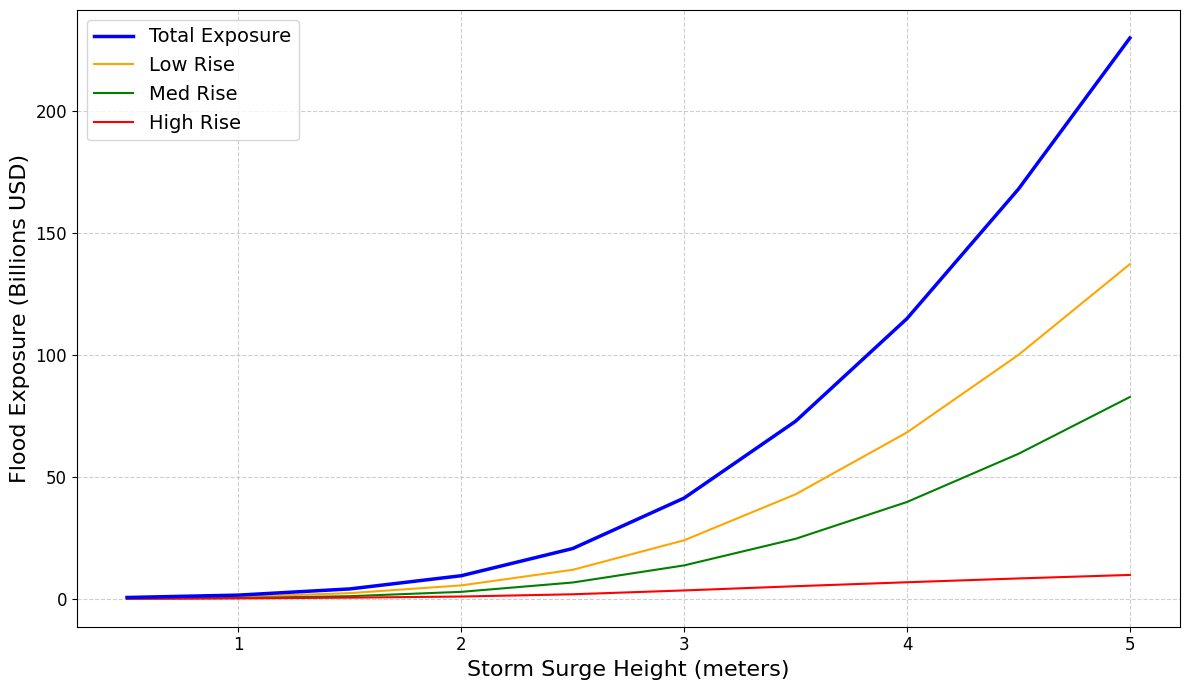

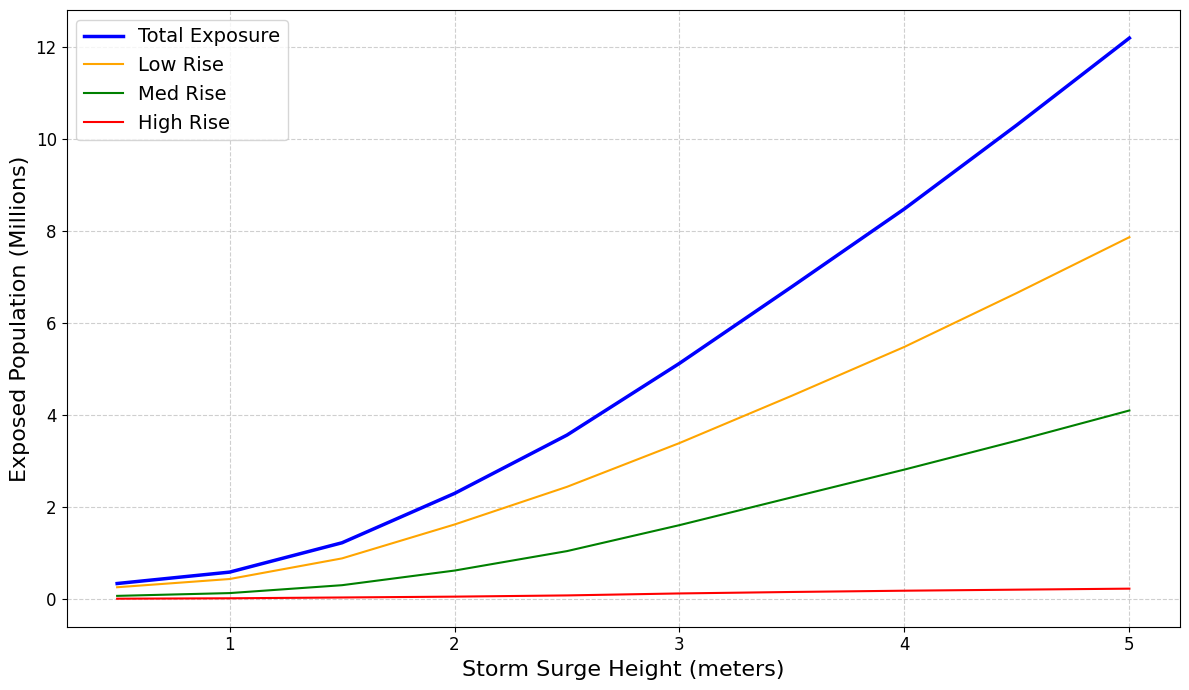

In [17]:
def plot_total_exposure(data, metric="damage", suffix=DAMAGE_SUFFIX):
    """Plot total exposure by building-height class and surge height."""
    configurations = {
        "damage": {
            "patterns": {
                "Low Rise": "L_{h}_{suffix}",
                "Med Rise": "M_{h}_{suffix}",
                "High Rise": "H_{h}_{suffix}",
                "Total Exposure": "A_{h}_{suffix}",
            },
            "scale": 1e9,
            "ylabel": "Flood Exposure (Billions USD)",
        },
        "population": {
            "patterns": {
                "Low Rise": "L_pop_{h}_2020",
                "Med Rise": "M_pop_{h}_2020",
                "High Rise": "H_pop_{h}_2020",
                "Total Exposure": "Pop_{h}_2020",
            },
            "scale": 1e6,
            "ylabel": "Exposed Population (Millions)",
        },
    }

    if metric not in configurations:
        raise ValueError("metric must be 'damage' or 'population'.")

    config = configurations[metric]
    colors = {
        "Low Rise": "orange",
        "Med Rise": "green",
        "High Rise": "red",
        "Total Exposure": "blue",
    }

    fig, ax = plt.subplots(figsize=(12, 7))

    for label, pattern in config["patterns"].items():
        columns = [
            pattern.format(h=f"{height:02d}", suffix=suffix)
            for height in HEIGHT_CODES
        ]
        require_columns(data, columns)

        numeric_data = data[columns].apply(pd.to_numeric, errors="raise")
        totals = numeric_data.sum(min_count=1) / config["scale"]

        ax.plot(
            HEIGHTS_M,
            totals.to_numpy(),
            label=label,
            color=colors[label],
            linewidth=2.5 if label == "Total Exposure" else 1.5,
        )

    ax.set_xlabel("Storm Surge Height (meters)", fontsize=16)
    ax.set_ylabel(config["ylabel"], fontsize=16)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.tick_params(axis="both", labelsize=12)
    ax.grid(True, linestyle="--", alpha=0.6)

    handles, labels = ax.get_legend_handles_labels()
    order = [3, 0, 1, 2]
    ax.legend(
        [handles[index] for index in order],
        [labels[index] for index in order],
        loc="best",
        fontsize=14,
    )

    fig.tight_layout()
    plt.show()
    return fig, ax


_ = plot_total_exposure(data=joined_df, metric="damage")
_ = plot_total_exposure(data=joined_df, metric="population")

# MSA aggregation and threshold interpolation 

In [20]:
def _calculate_interpolated_threshold(
    target_value, known_values, known_depths_m
):
    """Return the first interpolated height reaching a target exposure."""
    values = np.asarray(known_values, dtype=float)
    depths = np.asarray(known_depths_m, dtype=float)

    if values.size != depths.size or values.size < 2:
        raise ValueError("Values and depths must have equal length >= 2.")

    if not (
        np.isfinite(target_value)
        and np.isfinite(values).all()
        and np.isfinite(depths).all()
    ):
        return np.nan

    if np.any(np.diff(depths) <= 0):
        raise ValueError("Depths must be strictly increasing.")

    if np.any(np.diff(values) < 0):
        warnings.warn(
            "Exposure is not monotonically increasing; "
            "the threshold is unavailable.",
            stacklevel=2,
        )
        return np.nan

    if target_value < values[0] or target_value > values[-1]:
        return np.nan

    index = np.searchsorted(values, target_value, side="left")

    if index == 0 or values[index] == target_value:
        return float(depths[index])

    fraction = (
        (target_value - values[index - 1])
        / (values[index] - values[index - 1])
    )

    return float(
        depths[index - 1]
        + fraction * (depths[index] - depths[index - 1])
    )


def detect_height_columns(columns, pattern):
    """Return (height code, column name) pairs sorted by height."""
    expression = re.compile(pattern)
    matches = []

    for column in columns:
        match = expression.fullmatch(str(column))
        if match:
            matches.append((int(match.group(1)), column))

    return sorted(matches)


def analyze_msa_data(
    data,
    cbsa_data,
    flood_damage_percentage=0.05,
    inundated_pop_percentage=0.05,
    suffix=DAMAGE_SUFFIX,
):
    """
    Aggregate tract data to MSAs and calculate exposure thresholds.

    data is a dictionary mapping normalized MSA names to tract DataFrames.
    Fractions use exposure at each metric's highest available surge height.
    Zero exposure at 0 m is assumed.
    """
    for value in [flood_damage_percentage, inundated_pop_percentage]:
        if not 0 <= value <= 1:
            raise ValueError("Threshold fractions must be between 0 and 1.")

    all_columns = {
        column
        for frame in data.values()
        if not frame.empty
        for column in frame.columns
    }

    damage_columns = detect_height_columns(
        all_columns, rf"A_(\d{{2}})_{re.escape(str(suffix))}"
    )
    population_columns = detect_height_columns(
        all_columns, r"Pop_(\d{2})_2020"
    )

    if not damage_columns or not population_columns:
        raise ValueError("No damage or population height columns found.")

    name_map = {}
    for cbsa_id, info in cbsa_data.items():
        name = info.get("cbsa_name", f"Unknown MSA {cbsa_id}")
        name_map[clean_name_for_variable(name)] = name

    exposure_columns = [
        column for _, column in damage_columns + population_columns
    ]
    numeric_columns = [
        "Total_Property_Value",
        "Total_Pop",
        *exposure_columns,
    ]

    results = []

    for msa_key, frame in data.items():
        if frame.empty:
            continue

        require_columns(frame, ["FEMA_region", *numeric_columns])

        numeric_data = frame[numeric_columns].apply(
            pd.to_numeric, errors="raise"
        )

        # Do not report a partial aggregate when a tract value is missing.
        totals = numeric_data.sum(min_count=len(frame))

        region_label = frame["FEMA_region"].iloc[0]

        row = {
            "MSA_Name": name_map.get(
                msa_key, msa_key.replace("_", " ").title()
            ),
            "FEMA_Region": region_label,
            "Total_Property_Value": totals["Total_Property_Value"],
            "Total_Population": totals["Total_Pop"],
        }

        for pairs, fraction, output_column in [
            (
                damage_columns,
                flood_damage_percentage,
                "Damage_Threshold_Height",
            ),
            (
                population_columns,
                inundated_pop_percentage,
                "Population_Threshold_Height",
            ),
        ]:
            depths = [height / 10 for height, _ in pairs]
            values = [totals[column] for _, column in pairs]

            if depths[0] > 0:
                depths = [0.0, *depths]
                values = [0.0, *values]

            maximum_exposure = values[-1]
            threshold = np.nan

            if np.isfinite(maximum_exposure) and maximum_exposure > 0:
                threshold = _calculate_interpolated_threshold(
                    target_value=maximum_exposure * fraction,
                    known_values=values,
                    known_depths_m=depths,
                )

            row[output_column] = threshold

        row.update({column: totals[column] for column in exposure_columns})
        results.append(row)

    if not results:
        raise ValueError("No nonempty MSA datasets were available.")

    return pd.DataFrame(results)


final_summary_df = analyze_msa_data(
    data=msa_tract_dataframes,
    cbsa_data=msa_data,
    flood_damage_percentage=DAMAGE_THRESHOLD_FRACTION,
    inundated_pop_percentage=POPULATION_THRESHOLD_FRACTION,
)

# Sensitivity group classification

In [22]:
def select_sensitivity_groups(data, group_size=3):
    """Select nonoverlapping low-, middle-, and high-threshold groups."""
    require_columns(data, ["MSA_Name", "Damage_Threshold_Height"])

    if not isinstance(group_size, int) or group_size < 1:
        raise ValueError("group_size must be a positive integer.")

    if data["MSA_Name"].isna().any():
        raise ValueError("MSA_Name must not contain missing values.")

    if data["MSA_Name"].duplicated().any():
        raise ValueError("Expected exactly one summary row per MSA.")

    ranked = data[["MSA_Name", "Damage_Threshold_Height"]].copy()
    ranked["Damage_Threshold_Height"] = pd.to_numeric(
        ranked["Damage_Threshold_Height"], errors="raise"
    )

    ranked = ranked.loc[
        np.isfinite(ranked["Damage_Threshold_Height"])
    ].sort_values(
        ["Damage_Threshold_Height", "MSA_Name"]
    ).reset_index(drop=True)

    count = len(ranked)

    if count < 3:
        raise ValueError("At least three valid MSA thresholds are required.")

    effective_size = min(group_size, count // 3)

    if effective_size < group_size:
        warnings.warn(
            f"Reducing group size from {group_size} to {effective_size} "
            "to avoid overlapping groups.",
            stacklevel=2,
        )

    middle_start = count // 2 - effective_size // 2

    selected = {
        "High Sensitivity Group": ranked.iloc[:effective_size],
        "Medium Sensitivity Group": ranked.iloc[
            middle_start:middle_start + effective_size
        ],
        "Low Sensitivity Group": ranked.iloc[-effective_size:],
    }

    groups = {
        label: frame["MSA_Name"].tolist()
        for label, frame in selected.items()
    }

    ranges = {
        label: (
            frame["Damage_Threshold_Height"].min(),
            frame["Damage_Threshold_Height"].max(),
        )
        for label, frame in selected.items()
    }

    return groups, ranges


sensitivity_groups, sensitivity_ranges = select_sensitivity_groups(
    data=final_summary_df,
    group_size=GROUP_SIZE,
)

for label, names in sensitivity_groups.items():
    print(f"{label} (n={len(names)}): {', '.join(names)}")

High Sensitivity Group (n=3): Bangor, ME Metro Area, New Orleans-Metairie, LA Metro Area, Hammond, LA Metro Area
Medium Sensitivity Group (n=3): Palm Bay-Melbourne-Titusville, FL Metro Area, Pensacola-Ferry Pass-Brent, FL Metro Area, Naples-Marco Island, FL Metro Area
Low Sensitivity Group (n=3): Hilton Head Island-Bluffton-Port Royal, SC Metro Area, Greenville, NC Metro Area, Boston-Cambridge-Newton, MA-NH Metro Area


# Flood impact sensitivity plots

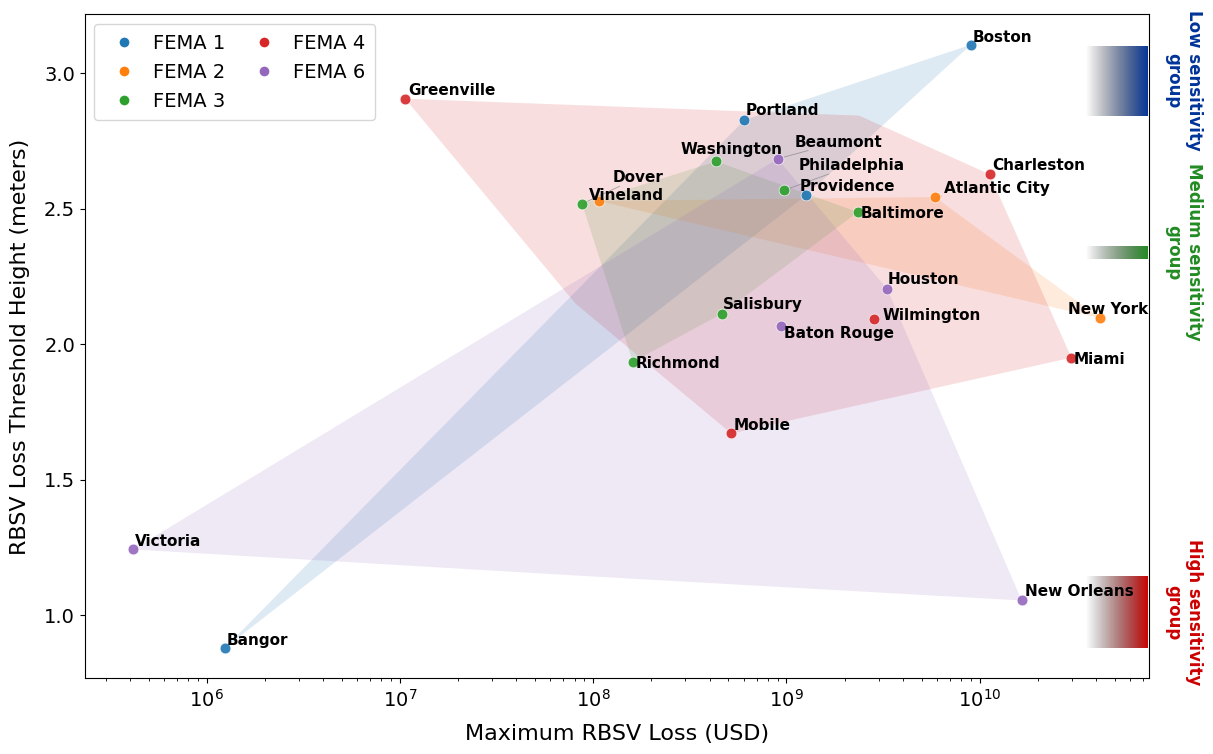

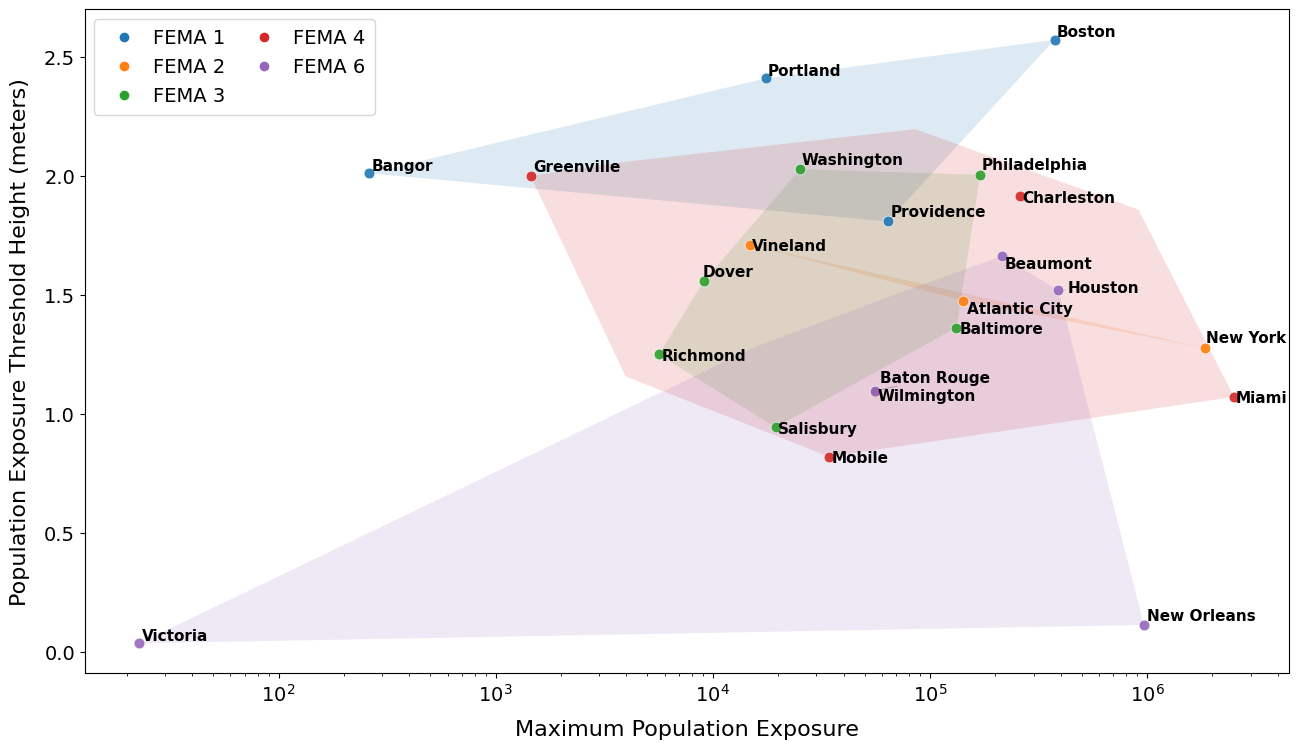

In [25]:

# ---------------------------------------------------------------------
# 1. Add sensitivity bands to the damage plot only
# ---------------------------------------------------------------------
def add_fading_bands(ax, ranges):
    """
    Draw sensitivity bands in the rightmost 6% of the axes.

    Horizontal positions use axes coordinates; vertical positions use
    threshold heights in meters.
    """
    original_xlim = ax.get_xlim()
    original_ylim = ax.get_ylim()

    gradient = np.linspace(0, 1, 100).reshape(1, -1)

    band_settings = {
        "High Sensitivity Group": (
            "#CC0000",
            "High sensitivity\ngroup",
        ),
        "Medium Sensitivity Group": (
            "#228B22",
            "Medium sensitivity\ngroup",
        ),
        "Low Sensitivity Group": (
            "#003399",
            "Low sensitivity\ngroup",
        ),
    }

    for group_name, (color, label) in band_settings.items():
        lower, upper = ranges[group_name]
        midpoint = (lower + upper) / 2

        if upper > lower:
            cmap = LinearSegmentedColormap.from_list(
                f"fade_{group_name}",
                [(0, 0, 0, 0), color],
            )

            ax.imshow(
                gradient,
                extent=(0.94, 1.0, lower, upper),
                transform=ax.get_yaxis_transform(),
                aspect="auto",
                origin="lower",
                cmap=cmap,
                zorder=1,
            )
        else:
            # Show a line if all selected thresholds are identical.
            ax.plot(
                [0.94, 1.0],
                [midpoint, midpoint],
                transform=ax.get_yaxis_transform(),
                color=color,
                linewidth=2,
                zorder=1,
            )

        ax.text(
            1.015,
            midpoint,
            label,
            transform=ax.get_yaxis_transform(),
            rotation=270,
            va="center",
            ha="left",
            multialignment="center",
            color=color,
            fontsize=12,
            fontweight="bold",
            clip_on=False,
        )

    ax.set_xlim(original_xlim)
    ax.set_ylim(original_ylim)


# ---------------------------------------------------------------------
# 2. Draw FEMA-region convex hulls
# ---------------------------------------------------------------------
def add_region_hulls(data, ax, x_column, y_column, color_map):
    """Compute convex hulls in log-x space and draw them in data space."""
    for region in REGION_ORDER:
        region_data = data.loc[data["FEMA_Region"] == region]

        if len(region_data) < 3:
            continue

        points = np.column_stack(
            [
                np.log10(
                    region_data[x_column].to_numpy(dtype=float)
                ),
                region_data[y_column].to_numpy(dtype=float),
            ]
        )

        points = np.unique(points, axis=0)

        # A two-dimensional hull requires three non-collinear points.
        if (
            len(points) < 3
            or np.linalg.matrix_rank(points - points[0]) < 2
        ):
            continue

        try:
            hull = ConvexHull(points)
        except QhullError:
            warnings.warn(
                f"Skipping the convex hull for {region}: "
                "the point geometry could not form a valid hull.",
                stacklevel=2,
            )
            continue

        vertices = points[hull.vertices].copy()
        vertices[:, 0] = 10 ** vertices[:, 0]

        ax.add_patch(
            Polygon(
                vertices,
                facecolor=color_map[region],
                edgecolor="none",
                alpha=0.15,
                zorder=0,
            )
        )


# ---------------------------------------------------------------------
# 3. Generate damage and population plots
# ---------------------------------------------------------------------
def generate_risk_plots_selected_msas_log(
    data,
    use_adjusttext=True,
    group_size=3,
    suffix=DAMAGE_SUFFIX,
):
    """
    Generate two selected-MSA scatterplots with log-scaled x-axes.

    Damage:
        Maximum RBSV loss versus damage threshold height.
        Includes damage-based sensitivity bands.

    Population:
        Maximum population exposure versus population threshold height.
        Does not include sensitivity bands.

    Regional hulls use all valid MSAs; visible points and labels use only
    the selected MSA names.
    """
    if not isinstance(data, pd.DataFrame) or data.empty:
        raise ValueError("data must be a nonempty pandas DataFrame.")

    damage_x_column = f"A_50_{suffix}"

    require_columns(
        data,
        [
            "MSA_Name",
            "FEMA_Region",
            damage_x_column,
            "Damage_Threshold_Height",
            "Pop_50_2020",
            "Population_Threshold_Height",
        ],
    )

    data = data.copy()

    data["FEMA_Region"] = (
        data["FEMA_Region"]
        .astype("string")
        .str.strip()
        .fillna("Other")
    )

    # Combined region labels must be corrected in Cell 4, not silently
    # reassigned or hidden in the legend.
    combined_regions = data.loc[
        data["FEMA_Region"].str.contains("/", regex=False),
        "FEMA_Region",
    ].unique()

    if len(combined_regions) > 0:
        raise ValueError(
            "Combined FEMA labels remain in final_summary_df: "
            f"{list(combined_regions)}. "
            "Restore the first-tract FEMA assignment in Cell 4 "
            "and rerun Cell 4 before running Cell 6."
        )

    unexpected_regions = (
        set(data["FEMA_Region"]) - set(REGION_ORDER) - {"Other"}
    )

    if unexpected_regions:
        raise ValueError(
            f"Unexpected FEMA labels: {sorted(unexpected_regions)}"
        )

    # Stable colors for the five FEMA regions.
    color_map = dict(
        zip(
            REGION_ORDER,
            sns.color_palette(n_colors=len(REGION_ORDER)),
        )
    )

    # Shared damage-based grouping, used only for the damage bands.
    _, damage_ranges = select_sensitivity_groups(
        data=data,
        group_size=group_size,
    )

    plot_settings = [
        {
            "x": damage_x_column,
            "y": "Damage_Threshold_Height",
            "xlabel": "Maximum RBSV Loss (USD)",
            "ylabel": "RBSV Loss Threshold Height (meters)",
            "show_bands": True,
        },
        {
            "x": "Pop_50_2020",
            "y": "Population_Threshold_Height",
            "xlabel": "Maximum Population Exposure",
            "ylabel": "Population Exposure Threshold Height (meters)",
            "show_bands": False,
        },
    ]

    figures = []

    for settings in plot_settings:
        x_column = settings["x"]
        y_column = settings["y"]

        # Prepare valid observations for this plot.
        plot_data = data.copy()

        plot_data[[x_column, y_column]] = plot_data[
            [x_column, y_column]
        ].apply(pd.to_numeric, errors="raise")

        valid = (
            np.isfinite(plot_data[x_column])
            & np.isfinite(plot_data[y_column])
            & (plot_data[x_column] > 0)
        )

        plot_data = plot_data.loc[valid].copy()

        if plot_data.empty:
            warnings.warn(
                f"No valid observations for {y_column}; skipping plot.",
                stacklevel=2,
            )
            continue

        plot_data["_short_name"] = plot_data["MSA_Name"].map(
            get_short_msa_name
        )

        display_data = plot_data.loc[
            plot_data["_short_name"].isin(MSAS_TO_LABEL)
        ].copy()

        fig, ax = plt.subplots(figsize=(14, 8))
        ax.set_xscale("log")

        # Convex hulls use all valid observations in each region.
        add_region_hulls(
            data=plot_data,
            ax=ax,
            x_column=x_column,
            y_column=y_column,
            color_map=color_map,
        )

        # Scatter only the selected MSAs.
        for region in REGION_ORDER:
            region_data = display_data.loc[
                display_data["FEMA_Region"] == region
            ]

            ax.scatter(
                region_data[x_column],
                region_data[y_column],
                color=color_map[region],
                alpha=0.9,
                s=60,
                edgecolors="white",
                linewidths=0.5,
                zorder=3,
            )

        # Keep unassigned MSAs visible without inventing a FEMA category.
        other_data = display_data.loc[
            display_data["FEMA_Region"] == "Other"
        ]

        if not other_data.empty:
            ax.scatter(
                other_data[x_column],
                other_data[y_column],
                color="gray",
                marker="x",
                s=60,
                zorder=3,
            )

            warnings.warn(
                "Selected MSAs with FEMA_Region='Other' are shown "
                "as gray crosses, outside the five-region legend.",
                stacklevel=2,
            )

        # Include all valid observations when determining plot limits.
        ax.update_datalim(
            plot_data[[x_column, y_column]].to_numpy(dtype=float)
        )
        ax.autoscale_view()

        # IMPORTANT: No sensitivity bands on the population plot.
        if settings["show_bands"]:
            add_fading_bands(ax, damage_ranges)

        texts = [
            ax.text(
                row[x_column],
                row[y_column],
                row["_short_name"],
                fontsize=11,
                fontweight="semibold",
                zorder=4,
            )
            for _, row in display_data.iterrows()
        ]

        ax.set_xlabel(
            settings["xlabel"],
            fontsize=16,
            labelpad=10,
        )
        ax.set_ylabel(
            settings["ylabel"],
            fontsize=16,
            labelpad=10,
        )

        ax.tick_params(axis="both", which="major", labelsize=14)
        ax.grid(False)

        # Explicit handles ensure exactly five consistent FEMA entries.
        legend_handles = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markerfacecolor=color_map[region],
                markeredgecolor="white",
                markersize=8,
                label=region,
            )
            for region in REGION_ORDER
        ]

        ax.legend(
            handles=legend_handles,
            title=None,
            loc="upper left",
            fontsize=14,
            ncol=2,
            columnspacing=1.0,
            handletextpad=0.5,
            borderpad=0.5,
        )

        # Reserve extra room only when outside band labels are present.
        fig.subplots_adjust(
            left=0.10,
            right=0.86 if settings["show_bands"] else 0.96,
            bottom=0.12,
            top=0.95,
        )

        # Adjust labels after finalizing the axes layout.
        if use_adjusttext and texts:
            fig.canvas.draw()

            adjust_text(
                texts,
                ax=ax,
                arrowprops={
                    "arrowstyle": "-",
                    "color": "gray",
                    "lw": 0.6,
                    "alpha": 0.7,
                },
            )

        plt.show()
        figures.append((fig, ax))

    return figures


# ---------------------------------------------------------------------
# 4. Generate both figures
# ---------------------------------------------------------------------
risk_figures = generate_risk_plots_selected_msas_log(
    data=final_summary_df,
    use_adjusttext=True,
    group_size=GROUP_SIZE,
)

# Shared calculations and grouped-curve plotting

In [29]:
def extract_height_matrix(data, pattern):
    """Return an MSA-by-height numeric matrix with heights in meters."""
    require_columns(data, ["MSA_Name"])

    if data["MSA_Name"].duplicated().any():
        raise ValueError("Expected exactly one summary row per MSA.")

    columns = [
        pattern.format(h=f"{height:02d}")
        for height in HEIGHT_CODES
    ]
    require_columns(data, columns)

    matrix = (
        data.set_index("MSA_Name")[columns]
        .apply(pd.to_numeric, errors="raise")
        .astype(float)
    )
    matrix.columns = HEIGHTS_M

    return matrix.replace([np.inf, -np.inf], np.nan)


def prepare_inundated_area_matrix(data, msa_names):
    """
    Return an MSA-by-height flooded-area matrix.

    """
    require_columns(data, ["MSA", "SurgeHeight", "FloodedArea_ksq"])

    data = data[["MSA", "SurgeHeight", "FloodedArea_ksq"]].copy()
    data["_msa_key"] = data["MSA"].map(normalize_msa_name)
    data["SurgeHeight"] = pd.to_numeric(
        data["SurgeHeight"], errors="raise"
    )
    data["FloodedArea_ksq"] = pd.to_numeric(
        data["FloodedArea_ksq"], errors="raise"
    )

    msa_names = pd.Index(msa_names, name="MSA_Name")
    msa_keys = [normalize_msa_name(name) for name in msa_names]

    if len(set(msa_keys)) != len(msa_keys):
        raise ValueError("MSA names collide after normalization.")

    data = data.loc[
        data["_msa_key"].isin(msa_keys)
        & data["SurgeHeight"].isin(HEIGHT_CODES)
    ].copy()

    duplicates = data.duplicated(
        ["_msa_key", "SurgeHeight"], keep=False
    )
    if duplicates.any():
        examples = data.loc[
            duplicates, ["MSA", "SurgeHeight"]
        ].head().to_dict("records")
        raise ValueError(
            "Multiple flooded-area records for an MSA and height. "
            f"Filter to the intended scenario first. Examples: {examples}"
        )

    area = data.pivot(
        index="_msa_key",
        columns="SurgeHeight",
        values="FloodedArea_ksq",
    ).reindex(index=msa_keys, columns=HEIGHT_CODES)

    area.index = msa_names
    area.columns = HEIGHTS_M
    area = area.replace([np.inf, -np.inf], np.nan)

    missing_names = area.index[area.isna().all(axis=1)].tolist()
    if missing_names:
        warnings.warn(
            f"No usable flooded-area records for: {missing_names}",
            stacklevel=2,
        )

    return area


def plot_grouped_curves(data, groups, ylabel, show_legend=True):
    """
    Plot an unweighted mean across available MSAs and a min–max band.

    data has MSA names as its index and surge heights as its columns.
    Missing values are excluded separately at each height.
    """
    fig, ax = plt.subplots(figsize=(12, 8))

    for label, msa_names in groups.items():
        group_data = data.reindex(msa_names)
        style = GROUP_STYLES[label]

        if not group_data.notna().to_numpy().any():
            warnings.warn(
                f"No valid curve values for {label}.",
                stacklevel=2,
            )
            continue

        valid_counts = group_data.notna().sum(axis=0)
        if (valid_counts < len(msa_names)).any():
            warnings.warn(
                f"{label}: available MSA counts vary from "
                f"{valid_counts.min()} to {valid_counts.max()} "
                "across heights.",
                stacklevel=2,
            )

        minimum = group_data.min(axis=0).to_numpy(dtype=float)
        maximum = group_data.max(axis=0).to_numpy(dtype=float)
        mean = group_data.mean(axis=0).to_numpy(dtype=float)
        heights = group_data.columns.to_numpy(dtype=float)

        ax.fill_between(
            heights,
            minimum,
            maximum,
            color=style["fill"],
            alpha=0.35,
            label=f"{label} Range",
        )

        ax.plot(
            heights,
            mean,
            color=style["color"],
            marker=style["marker"],
            linewidth=2.5,
            markersize=8,
            label=f"{label} Mean",
        )

    ax.set_xlabel("Storm Surge Height (meters)", fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.tick_params(axis="both", labelsize=16)
    ax.grid(True, linestyle="--", alpha=0.5)

    if show_legend:
        ax.legend(loc="upper left", fontsize=12, frameon=True)

    fig.tight_layout()
    plt.show()
    return fig, ax

# Storm surge impact by MSA sensitivity group

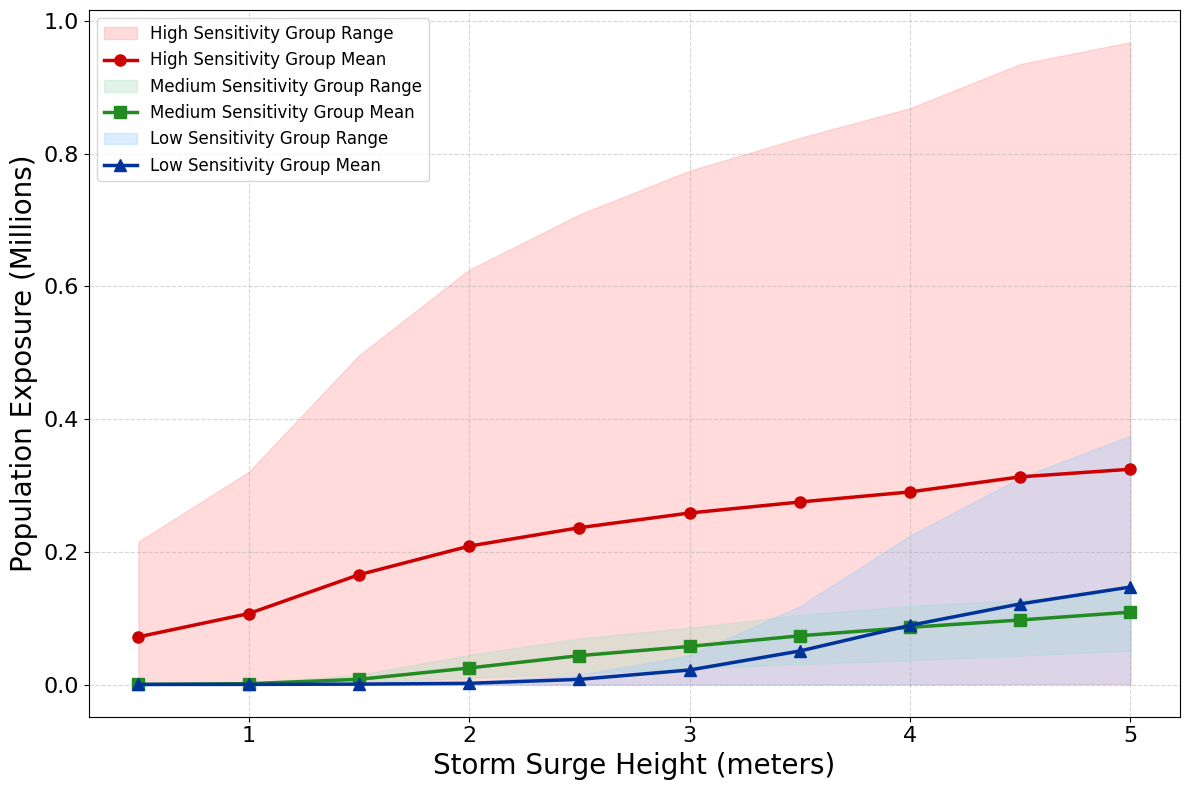

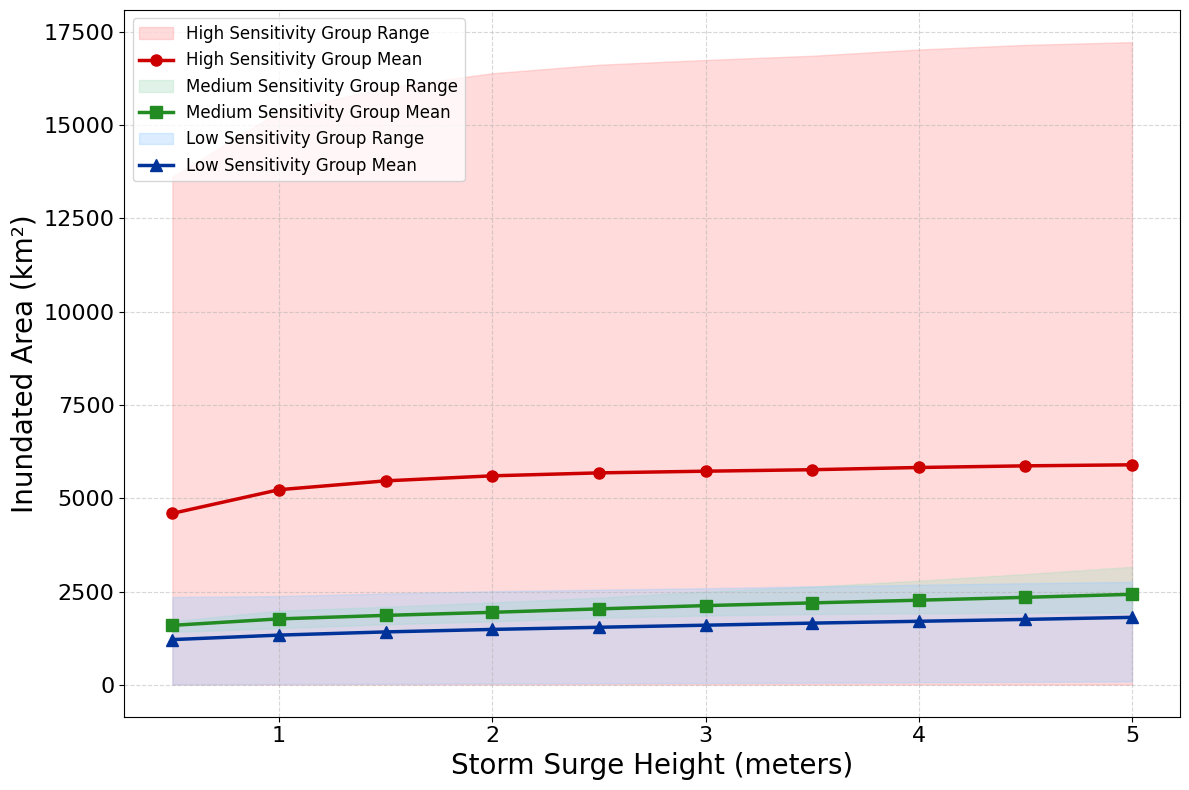

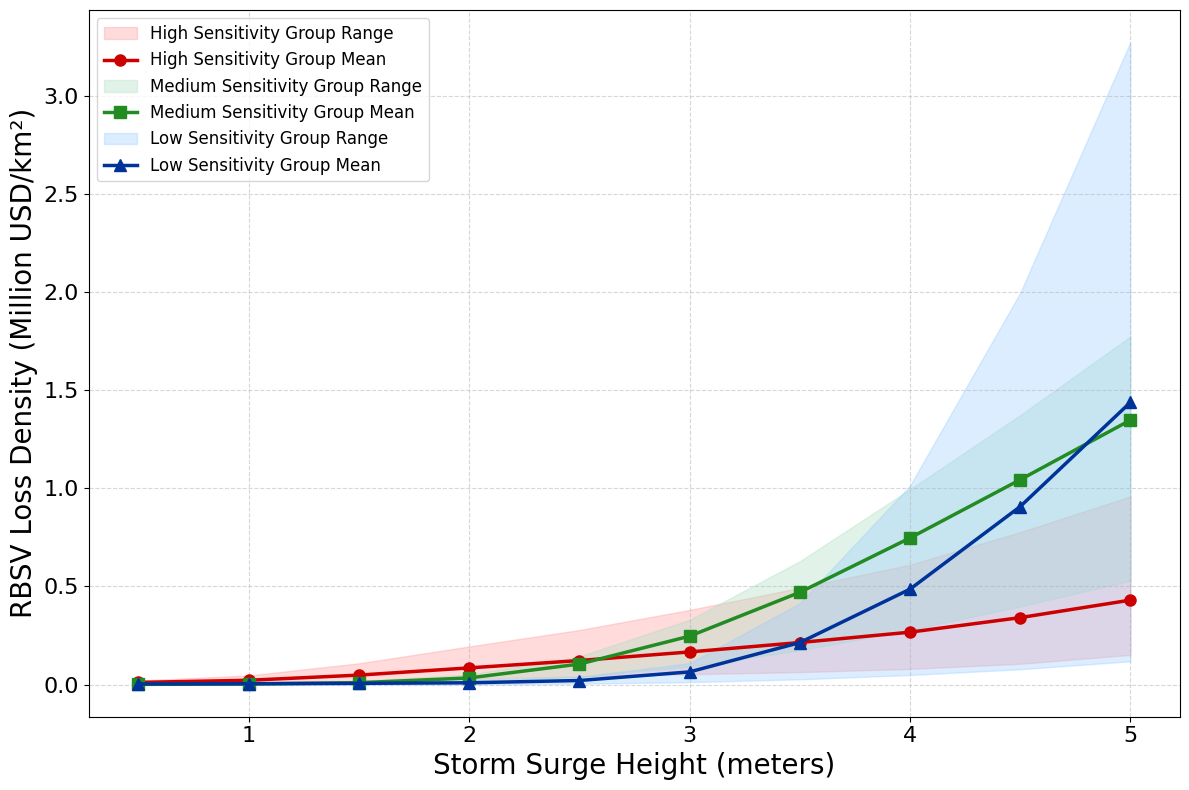

C:\Users\wanh535\AppData\Local\Temp\ipykernel_25360\2646410593.py:153: UserWarning: Low Sensitivity Group: available MSA counts vary from 2 to 3 across heights.
  return plot_grouped_curves(


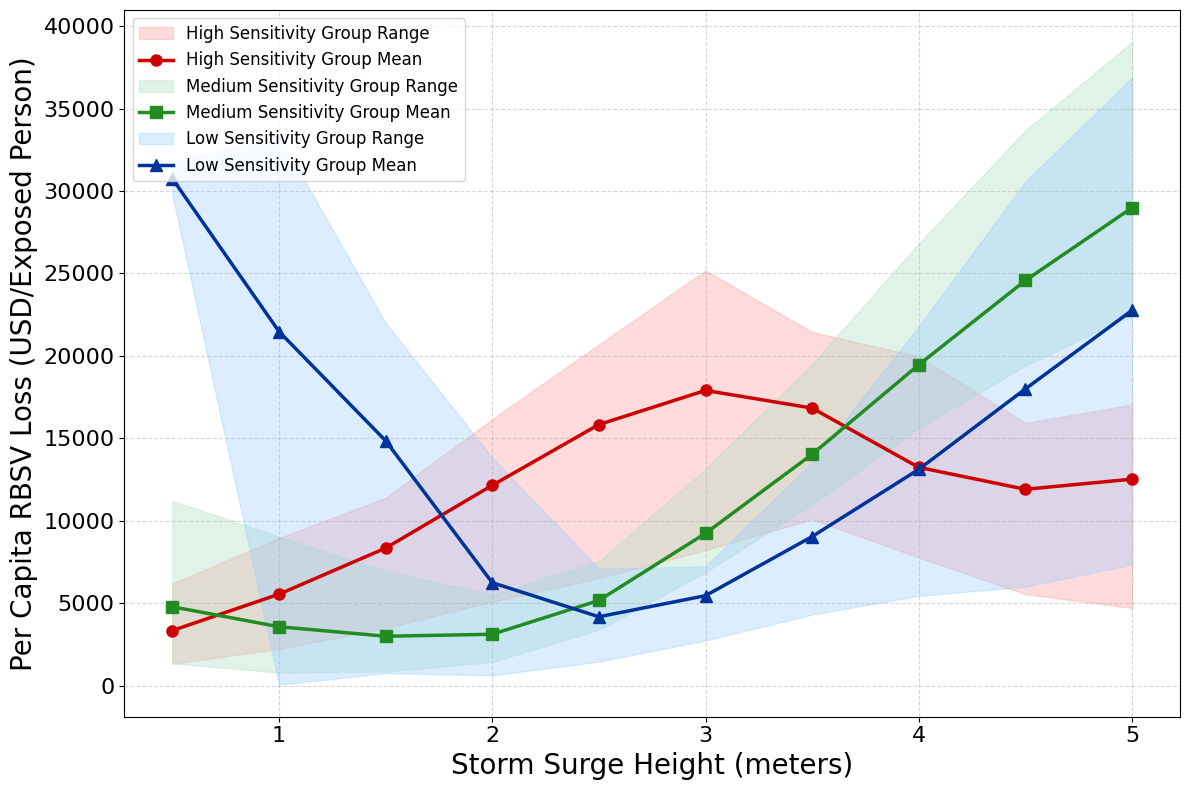

In [31]:

# ---------------------------------------------------------------------
# 1. Population exposure
# ---------------------------------------------------------------------
def plot_grouped_inundated_population_2020(
    data,
    group_size=3,
    show_legend=True,
):
    """Plot exposed population in millions by sensitivity group."""
    groups, _ = select_sensitivity_groups(
        data=data,
        group_size=group_size,
    )

    population = extract_height_matrix(
        data=data,
        pattern="Pop_{h}_2020",
    )

    curves = population / 1e6

    return plot_grouped_curves(
        data=curves,
        groups=groups,
        ylabel="Population Exposure (Millions)",
        show_legend=show_legend,
    )


# ---------------------------------------------------------------------
# 2. Inundated area
# ---------------------------------------------------------------------
def plot_grouped_inundated_area(
    data,
    inundated_area_data,
    group_size=3,
    show_legend=True,
):
    """
    Plot inundated area in km² by sensitivity group.

    Assumes FloodedArea_ksq is in km² and SurgeHeight is in decimeters.
    Zero area is retained; missing or negative area is unavailable.
    """
    groups, _ = select_sensitivity_groups(
        data=data,
        group_size=group_size,
    )

    selected_names = [
        name
        for names in groups.values()
        for name in names
    ]

    area = prepare_inundated_area_matrix(
        data=inundated_area_data,
        msa_names=selected_names,
    )

    curves = area.where(area >= 0)

    return plot_grouped_curves(
        data=curves,
        groups=groups,
        ylabel="Inundated Area (km²)",
        show_legend=show_legend,
    )


# ---------------------------------------------------------------------
# 3. RBSV loss density
# ---------------------------------------------------------------------
def plot_grouped_normalized_damage(
    data,
    inundated_area_data,
    suffix=DAMAGE_SUFFIX,
    group_size=3,
    show_legend=True,
):
    """
    Plot RBSV loss density in million USD/km² by sensitivity group.

    Density is calculated separately for each MSA and surge height.
    Missing or nonpositive inundated area produces an unavailable value.
    """
    groups, _ = select_sensitivity_groups(
        data=data,
        group_size=group_size,
    )

    selected_names = [
        name
        for names in groups.values()
        for name in names
    ]

    damage = extract_height_matrix(
        data=data,
        pattern=f"A_{{h}}_{suffix}",
    ).reindex(selected_names)

    area = prepare_inundated_area_matrix(
        data=inundated_area_data,
        msa_names=damage.index,
    )

    # Convert damage to million USD before dividing by area.
    curves = (damage / 1e6).div(area.where(area > 0))
    curves = curves.replace([np.inf, -np.inf], np.nan)

    return plot_grouped_curves(
        data=curves,
        groups=groups,
        ylabel="RBSV Loss Density (Million USD/km²)",
        show_legend=show_legend,
    )


# ---------------------------------------------------------------------
# 4. Per capita RBSV loss
# ---------------------------------------------------------------------
def plot_grouped_per_capita_damage(
    data,
    suffix=DAMAGE_SUFFIX,
    group_size=3,
    show_legend=True,
):
    """
    Plot RBSV loss per exposed person by sensitivity group.

    Following the original script, the denominator is exposed population
    at each surge height, not total MSA population.
    """
    groups, _ = select_sensitivity_groups(
        data=data,
        group_size=group_size,
    )

    damage = extract_height_matrix(
        data=data,
        pattern=f"A_{{h}}_{suffix}",
    )

    population = extract_height_matrix(
        data=data,
        pattern="Pop_{h}_2020",
    )

    curves = damage.div(population.where(population > 0))
    curves = curves.replace([np.inf, -np.inf], np.nan)

    return plot_grouped_curves(
        data=curves,
        groups=groups,
        ylabel="Per Capita RBSV Loss (USD/Exposed Person)",
        show_legend=show_legend,
    )


# ---------------------------------------------------------------------
# 5. Generate all four figures
# ---------------------------------------------------------------------

# Figure 1 — Population exposure
population_figure, population_ax = (
    plot_grouped_inundated_population_2020(
        data=final_summary_df,
        group_size=GROUP_SIZE,
    )
)

# Figure 2 — Inundated area
area_figure, area_ax = plot_grouped_inundated_area(
    data=final_summary_df,
    inundated_area_data=inundation_data,
    group_size=GROUP_SIZE,
)

# Figure 3 — RBSV loss density
density_figure, density_ax = plot_grouped_normalized_damage(
    data=final_summary_df,
    inundated_area_data=inundation_data,
    suffix=DAMAGE_SUFFIX,
    group_size=GROUP_SIZE,
)

# Figure 4 — Per capita RBSV loss
per_capita_figure, per_capita_ax = plot_grouped_per_capita_damage(
    data=final_summary_df,
    suffix=DAMAGE_SUFFIX,
    group_size=GROUP_SIZE,
)